In [5]:
import pandas as pd

In [6]:
# !unzip /content/Project.zip

Archive:  /content/Project.zip
replace BBC News Summary/News Articles/business/001.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [7]:
data=pd.read_csv("/content/bbc_news_complete.csv")

In [8]:
data

,category,article,summary
0,business,Ad sales boost Time Warner profit\n\nQuarterly...,TimeWarner said fourth quarter sales rose 2% t...
1,business,Dollar gains on Greenspan speech\n\nThe dollar...,The dollar has hit its highest level against t...
2,business,Yukos unit buyer faces loan claim\n\nThe owner...,Yukos' owner Menatep Group says it will ask Ro...
3,business,High fuel prices hit BA's profits\n\nBritish A...,"Rod Eddington, BA's chief executive, said the ..."
4,business,Pernod takeover talk lifts Domecq\n\nShares in...,Pernod has reduced the debt it took on to fund...
...,...,...,...
2220,tech,BT program to beat dialler scams\n\nBT is intr...,BT is introducing two initiatives to help beat...
2221,tech,Spam e-mails tempt net shoppers\n\nComputer us...,A third of them read unsolicited junk e-mail a...
2222,tech,Be careful how you code\n\nA new European dire...,This goes to the heart of the European project...
2223,tech,US cyber security chief resigns\n\nThe man mak...,Amit Yoran was director of the National Cyber ...


In [9]:
data.isnull().sum()

,0
category,0
article,0
summary,0


In [10]:
data.shape

(2225, 3)

In [11]:
data.head()

,category,article,summary
0,business,Ad sales boost Time Warner profit\n\nQuarterly...,TimeWarner said fourth quarter sales rose 2% t...
1,business,Dollar gains on Greenspan speech\n\nThe dollar...,The dollar has hit its highest level against t...
2,business,Yukos unit buyer faces loan claim\n\nThe owner...,Yukos' owner Menatep Group says it will ask Ro...
3,business,High fuel prices hit BA's profits\n\nBritish A...,"Rod Eddington, BA's chief executive, said the ..."
4,business,Pernod takeover talk lifts Domecq\n\nShares in...,Pernod has reduced the debt it took on to fund...


In [12]:
data.tail()

,category,article,summary
2220,tech,BT program to beat dialler scams\n\nBT is intr...,BT is introducing two initiatives to help beat...
2221,tech,Spam e-mails tempt net shoppers\n\nComputer us...,A third of them read unsolicited junk e-mail a...
2222,tech,Be careful how you code\n\nA new European dire...,This goes to the heart of the European project...
2223,tech,US cyber security chief resigns\n\nThe man mak...,Amit Yoran was director of the National Cyber ...
2224,tech,Losing yourself in online gaming\n\nOnline rol...,He says that in the world of online gaming suc...


In [13]:
data['article']=data['article'].replace(r'\n+','. ',regex=True)
data['summary']=data['summary'].replace(r'\n+','. ',regex=True)

In [14]:
data.tail()

,category,article,summary
2220,tech,BT program to beat dialler scams. BT is introd...,BT is introducing two initiatives to help beat...
2221,tech,Spam e-mails tempt net shoppers. Computer user...,A third of them read unsolicited junk e-mail a...
2222,tech,Be careful how you code. A new European direct...,This goes to the heart of the European project...
2223,tech,US cyber security chief resigns. The man makin...,Amit Yoran was director of the National Cyber ...
2224,tech,Losing yourself in online gaming. Online role ...,He says that in the world of online gaming suc...


In [15]:
data.head()

,category,article,summary
0,business,Ad sales boost Time Warner profit. Quarterly p...,TimeWarner said fourth quarter sales rose 2% t...
1,business,Dollar gains on Greenspan speech. The dollar h...,The dollar has hit its highest level against t...
2,business,Yukos unit buyer faces loan claim. The owners ...,Yukos' owner Menatep Group says it will ask Ro...
3,business,High fuel prices hit BA's profits. British Air...,"Rod Eddington, BA's chief executive, said the ..."
4,business,Pernod takeover talk lifts Domecq. Shares in U...,Pernod has reduced the debt it took on to fund...


In [16]:
!pip install nltk



In [17]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))
stop_words -= {'not', 'no', 'nor'}

stemmer = PorterStemmer()

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)

    words = text.split()

    words = [word for word in words if word not in stop_words]

    words = [stemmer.stem(word) for word in words]

    return " ".join(words)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [18]:
data

,category,article,summary
0,business,Ad sales boost Time Warner profit. Quarterly p...,TimeWarner said fourth quarter sales rose 2% t...
1,business,Dollar gains on Greenspan speech. The dollar h...,The dollar has hit its highest level against t...
2,business,Yukos unit buyer faces loan claim. The owners ...,Yukos' owner Menatep Group says it will ask Ro...
3,business,High fuel prices hit BA's profits. British Air...,"Rod Eddington, BA's chief executive, said the ..."
4,business,Pernod takeover talk lifts Domecq. Shares in U...,Pernod has reduced the debt it took on to fund...
...,...,...,...
2220,tech,BT program to beat dialler scams. BT is introd...,BT is introducing two initiatives to help beat...
2221,tech,Spam e-mails tempt net shoppers. Computer user...,A third of them read unsolicited junk e-mail a...
2222,tech,Be careful how you code. A new European direct...,This goes to the heart of the European project...
2223,tech,US cyber security chief resigns. The man makin...,Amit Yoran was director of the National Cyber ...


In [19]:
data

,category,article,summary
0,business,Ad sales boost Time Warner profit. Quarterly p...,TimeWarner said fourth quarter sales rose 2% t...
1,business,Dollar gains on Greenspan speech. The dollar h...,The dollar has hit its highest level against t...
2,business,Yukos unit buyer faces loan claim. The owners ...,Yukos' owner Menatep Group says it will ask Ro...
3,business,High fuel prices hit BA's profits. British Air...,"Rod Eddington, BA's chief executive, said the ..."
4,business,Pernod takeover talk lifts Domecq. Shares in U...,Pernod has reduced the debt it took on to fund...
...,...,...,...
2220,tech,BT program to beat dialler scams. BT is introd...,BT is introducing two initiatives to help beat...
2221,tech,Spam e-mails tempt net shoppers. Computer user...,A third of them read unsolicited junk e-mail a...
2222,tech,Be careful how you code. A new European direct...,This goes to the heart of the European project...
2223,tech,US cyber security chief resigns. The man makin...,Amit Yoran was director of the National Cyber ...


In [20]:
data

,category,article,summary
0,business,Ad sales boost Time Warner profit. Quarterly p...,TimeWarner said fourth quarter sales rose 2% t...
1,business,Dollar gains on Greenspan speech. The dollar h...,The dollar has hit its highest level against t...
2,business,Yukos unit buyer faces loan claim. The owners ...,Yukos' owner Menatep Group says it will ask Ro...
3,business,High fuel prices hit BA's profits. British Air...,"Rod Eddington, BA's chief executive, said the ..."
4,business,Pernod takeover talk lifts Domecq. Shares in U...,Pernod has reduced the debt it took on to fund...
...,...,...,...
2220,tech,BT program to beat dialler scams. BT is introd...,BT is introducing two initiatives to help beat...
2221,tech,Spam e-mails tempt net shoppers. Computer user...,A third of them read unsolicited junk e-mail a...
2222,tech,Be careful how you code. A new European direct...,This goes to the heart of the European project...
2223,tech,US cyber security chief resigns. The man makin...,Amit Yoran was director of the National Cyber ...


In [21]:
data

,category,article,summary
0,business,Ad sales boost Time Warner profit. Quarterly p...,TimeWarner said fourth quarter sales rose 2% t...
1,business,Dollar gains on Greenspan speech. The dollar h...,The dollar has hit its highest level against t...
2,business,Yukos unit buyer faces loan claim. The owners ...,Yukos' owner Menatep Group says it will ask Ro...
3,business,High fuel prices hit BA's profits. British Air...,"Rod Eddington, BA's chief executive, said the ..."
4,business,Pernod takeover talk lifts Domecq. Shares in U...,Pernod has reduced the debt it took on to fund...
...,...,...,...
2220,tech,BT program to beat dialler scams. BT is introd...,BT is introducing two initiatives to help beat...
2221,tech,Spam e-mails tempt net shoppers. Computer user...,A third of them read unsolicited junk e-mail a...
2222,tech,Be careful how you code. A new European direct...,This goes to the heart of the European project...
2223,tech,US cyber security chief resigns. The man makin...,Amit Yoran was director of the National Cyber ...


In [22]:
# import re

# def add_full_stop(text):
#     # Remove extra spaces
#     text = text.strip()

#     # Add a full stop only if the text doesn't already end with punctuation
#     if text and text[-1] not in '.!?':
#         text = text + '.'

#     return text

# data['article'] = data['article'].apply(add_full_stop)

In [23]:
data

,category,article,summary
0,business,Ad sales boost Time Warner profit. Quarterly p...,TimeWarner said fourth quarter sales rose 2% t...
1,business,Dollar gains on Greenspan speech. The dollar h...,The dollar has hit its highest level against t...
2,business,Yukos unit buyer faces loan claim. The owners ...,Yukos' owner Menatep Group says it will ask Ro...
3,business,High fuel prices hit BA's profits. British Air...,"Rod Eddington, BA's chief executive, said the ..."
4,business,Pernod takeover talk lifts Domecq. Shares in U...,Pernod has reduced the debt it took on to fund...
...,...,...,...
2220,tech,BT program to beat dialler scams. BT is introd...,BT is introducing two initiatives to help beat...
2221,tech,Spam e-mails tempt net shoppers. Computer user...,A third of them read unsolicited junk e-mail a...
2222,tech,Be careful how you code. A new European direct...,This goes to the heart of the European project...
2223,tech,US cyber security chief resigns. The man makin...,Amit Yoran was director of the National Cyber ...


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [25]:
print("Dataset Shape:", data.shape)

print("\nColumns:")
print(data.columns)

print("\nData Types:")
print(data.dtypes)

print("\nDataset Information:")
data.info()

print("\nStatistical Description:")
data.describe(include='all')

Dataset Shape: (2225, 3)

Columns:
Index(['category', 'article', 'summary'], dtype='object')

Data Types:
category    object
article     object
summary     object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  2225 non-null   object
 1   article   2225 non-null   object
 2   summary   2225 non-null   object
dtypes: object(3)
memory usage: 52.3+ KB

Statistical Description:


,category,article,summary
count,2225,2225,2225
unique,5,2127,2081
top,sport,SEC to rethink post-Enron rules. The US stock ...,The BDO optimism index - a leading indicator o...
freq,511,2,2


In [26]:
print(data['category'].unique())

print("\nCategory Counts:")
print(data['category'].value_counts())

['business' 'entertainment' 'politics' 'sport' 'tech']

Category Counts:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64


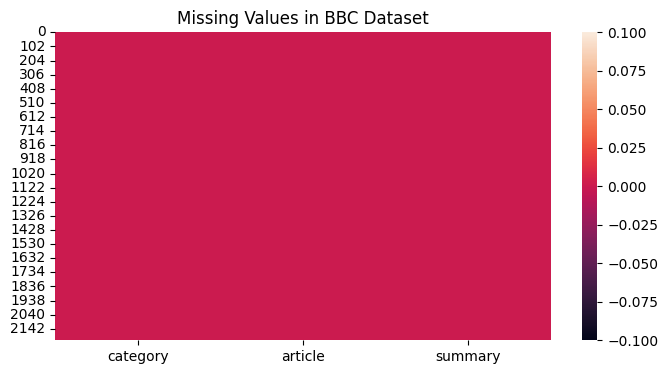

In [27]:
plt.figure(figsize=(8, 4))

sns.heatmap(data.isnull(), cbar=True)

plt.title("Missing Values in BBC Dataset")

plt.show()

In [28]:
print("Duplicate Rows:", data.duplicated().sum())

print("Duplicate Articles:", data['article'].duplicated().sum())

Duplicate Rows: 98
Duplicate Articles: 98


In [29]:
# Remove duplicate rows
data.drop_duplicates(inplace=True)

# Create the processed text column before using it
data['processed_article'] = data['article'].fillna('').astype(str).apply(preprocess_text)

# Remove rows with missing/empty article text or missing category
data.dropna(subset=['article', 'category'], inplace=True)
data = data[data['article'].str.strip() != '']
data = data[data['processed_article'].str.strip() != '']

data.reset_index(drop=True, inplace=True)

print("Final Dataset Shape:", data.shape)
print("\nMissing Values:")
print(data[['article', 'category', 'processed_article']].isnull().sum())

Final Dataset Shape: (2127, 4)

Missing Values:
article              0
category             0
processed_article    0
dtype: int64


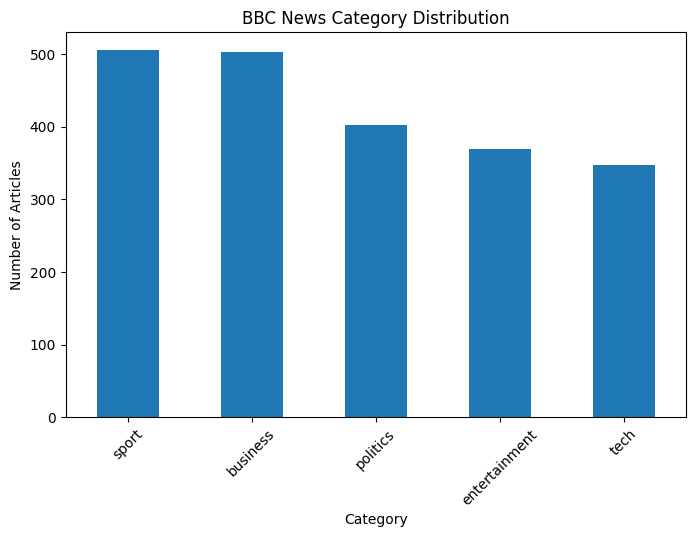

In [30]:
category_counts = data['category'].value_counts()

category_counts.plot(kind='bar', figsize=(8, 5))

plt.title("BBC News Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)

plt.show()

category
sport            23.74
business         23.65
politics         18.95
entertainment    17.35
tech             16.31
Name: proportion, dtype: float64


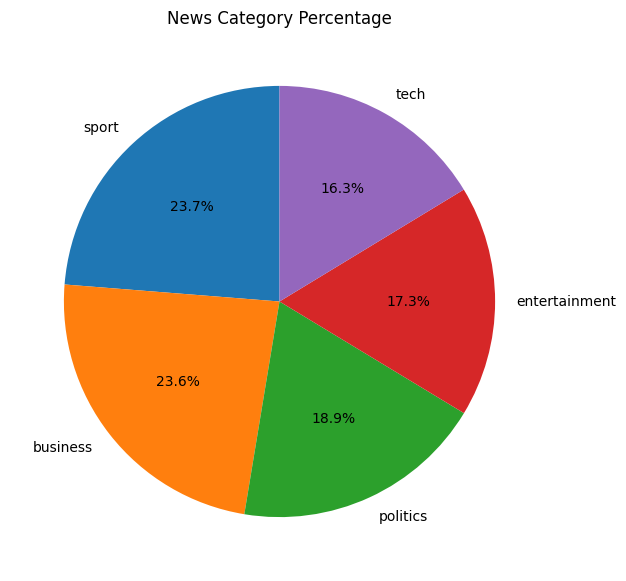

In [31]:
category_percentage = data['category'].value_counts(normalize=True) * 100

print(category_percentage.round(2))

plt.figure(figsize=(7, 7))

plt.pie(
    category_percentage,
    labels=category_percentage.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("News Category Percentage")

plt.show()

In [32]:
data['article_length'] = data['article'].apply(
    lambda text: len(str(text).split())
)

data[['category', 'article_length']].head()

,category,article_length
0,business,421
1,business,384
2,business,264
3,business,406
4,business,265


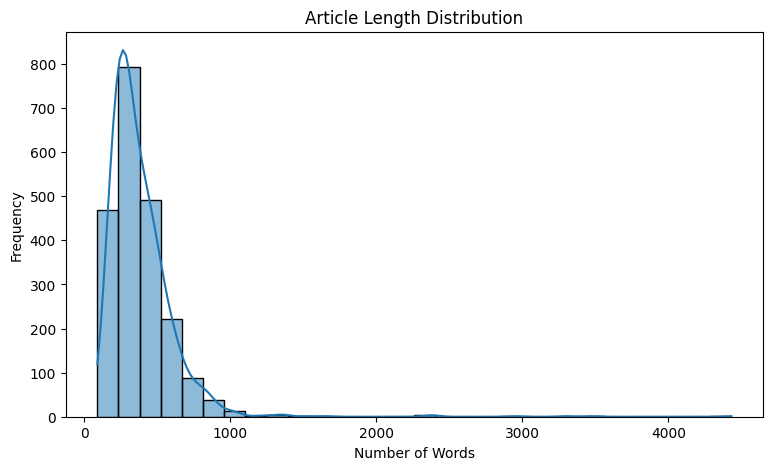

In [33]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data['article_length'],
    bins=30,
    kde=True
)

plt.title("Article Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [34]:
X = data['processed_article']

y = data['category']

print("Input Shape:", X.shape)

print("Output Shape:", y.shape)

Input Shape: (2127,)
Output Shape: (2127,)


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))

Training Records: 1701
Testing Records: 426


In [36]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

In [37]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

In [38]:
words = tfidf.get_feature_names_out()

print(words[:50])

['aaa' 'abandon' 'abba' 'abc' 'abil' 'abl' 'abolish' 'abort' 'abroad'
 'absenc' 'absolut' 'abus' 'ac' 'ac milan' 'academ' 'academi'
 'academi award' 'acceler' 'accept' 'access' 'accid' 'acclaim' 'accompani'
 'accord' 'accord mr' 'accord report' 'account' 'accur' 'accus' 'achiev'
 'acknowledg' 'acquir' 'acquisit' 'across' 'across countri' 'across europ'
 'act' 'action' 'activ' 'activist' 'actor' 'actress' 'actual' 'ad'
 'ad not' 'ad would' 'adam' 'adapt' 'add' 'addit']


In [39]:
idf_values = pd.DataFrame({
    'Word': tfidf.get_feature_names_out(),
    'IDF': tfidf.idf_
})

display(
    idf_values.sort_values(
        by='IDF',
        ascending=False
    ).head(20)
)

,Word,IDF
1383,espn,7.746412
4180,standard charter,7.746412
3578,regiment,7.746412
627,cash machin,7.746412
4096,song last,7.746412
89,ahold,7.746412
229,argonaut,7.746412
2810,mr forsyth,7.746412
171,anelka,7.340947
3562,reddi,7.340947


In [40]:
display(
    idf_values.sort_values(
        by='IDF',
        ascending=True
    ).head(20)
)

,Word,IDF
3761,said,1.165773
4969,year,1.419369
2978,not,1.491622
126,also,1.572626
4925,would,1.664193
3064,one,1.715727
4471,time,1.831559
2903,new,1.843779
2373,last,1.867277
4595,two,1.944294


In [41]:
tfidf_dataframe = pd.DataFrame(
    X_train_tfidf[:5].toarray(),
    columns=tfidf.get_feature_names_out()
)

display(tfidf_dataframe)

,aaa,abandon,abba,abc,abil,abl,abolish,abort,abroad,absenc,...,youth,yuan,yugansk,yuganskneftega,yuko,yuko claim,yushchenko,zealand,zero,zone
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.081425,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0


In [42]:
article_scores = X_train_tfidf[0].toarray()[0]

word_scores = pd.DataFrame({
    'Word': tfidf.get_feature_names_out(),
    'TF-IDF': article_scores
})

word_scores = word_scores.sort_values(
    by='TF-IDF',
    ascending=False
)

display(word_scores.head(15))

,Word,TF-IDF
3504,rail,0.523836
371,beatti,0.427867
20,accid,0.266610
4558,trial,0.194693
2418,leed,0.177740
3897,section,0.176207
678,charg,0.160991
2468,line,0.152822
2576,manag,0.140586
1140,die,0.136244


In [43]:
data.to_csv(
    "bbc_news_eda_completed.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [44]:
from sklearn.naive_bayes import MultinomialNB

In [45]:
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)
model

MultinomialNB()

In [46]:
y_pred = model.predict(X_test_tfidf)

print(y_pred[:10])

['tech' 'entertainment' 'sport' 'entertainment' 'politics' 'politics'
 'entertainment' 'business' 'business' 'entertainment']


In [47]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [48]:
comparison = pd.DataFrame({
    'Actual Category': y_test.values,
    'Predicted Category': y_pred
})

display(comparison.head(20))

,Actual Category,Predicted Category
0,tech,tech
1,entertainment,entertainment
2,sport,sport
3,entertainment,entertainment
4,politics,politics
5,politics,politics
6,entertainment,entertainment
7,business,business
8,business,business
9,entertainment,entertainment


In [49]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

               precision    recall  f1-score   support

     business       0.97      0.95      0.96       101
entertainment       0.99      0.97      0.98        74
     politics       0.96      0.98      0.97        81
        sport       1.00      1.00      1.00       101
         tech       0.94      0.97      0.96        69

     accuracy                           0.97       426
    macro avg       0.97      0.97      0.97       426
 weighted avg       0.97      0.97      0.97       426



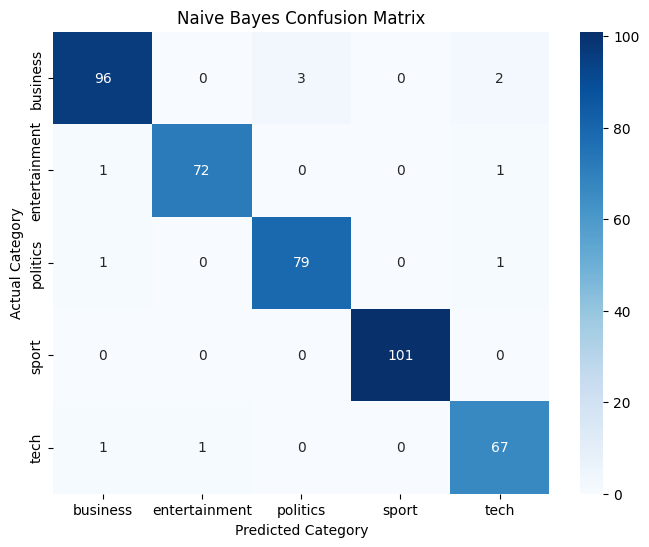

In [50]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Naive Bayes Confusion Matrix")

plt.show()

In [51]:
new_article = """
The government announced new economic policies.
The stock market increased following the announcement.
"""

# Apply the same preprocessing function
processed_text = preprocess_text(new_article)

# Convert text into TF-IDF
new_article_tfidf = tfidf.transform([processed_text])

# Predict category
prediction = model.predict(new_article_tfidf)

print("Predicted News Category:", prediction[0])

Predicted News Category: business


In [52]:
new_article = """
India secured an impressive victory against Australia in the international cricket match.
The Indian team scored 285 runs in the first innings.
The opening batsman played an excellent innings and scored a brilliant century.
The bowlers performed exceptionally well and took important wickets.
Australia struggled to chase the target and lost the match by 45 runs.
The captain praised the players for their teamwork and outstanding performance.
The next match will take place this weekend.
"""

# Preprocessing
processed_text = preprocess_text(new_article)

# TF-IDF Transformation
new_article_tfidf = tfidf.transform([processed_text])

# Predict Category
prediction = model.predict(new_article_tfidf)

print("Predicted News Category:", prediction[0])

Predicted News Category: sport


In [53]:
y_pred1 = lr_model.predict(X_test_tfidf)

print(y_pred1[:10])

['tech' 'entertainment' 'sport' 'entertainment' 'politics' 'politics'
 'entertainment' 'business' 'business' 'entertainment']


In [54]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred1))

print(classification_report(y_test, y_pred1))

Accuracy: 0.9835680751173709
               precision    recall  f1-score   support

     business       1.00      0.97      0.98       101
entertainment       0.96      1.00      0.98        74
     politics       0.98      0.99      0.98        81
        sport       1.00      1.00      1.00       101
         tech       0.97      0.96      0.96        69

     accuracy                           0.98       426
    macro avg       0.98      0.98      0.98       426
 weighted avg       0.98      0.98      0.98       426



In [55]:
new_article = "Developers developed one immortal software."

processed_article = preprocess_text(new_article)

article_tfidf = tfidf.transform([processed_article])

prediction = lr_model.predict(article_tfidf)

probabilities = lr_model.predict_proba(article_tfidf)

confidence = probabilities.max()

print("Predicted Category:", prediction[0])
print("Confidence:", round(confidence * 100, 2), "%")


Predicted Category: tech
Confidence: 55.87 %


In [56]:
from sklearn.metrics import accuracy_score, f1_score

nb_pred = model.predict(X_test_tfidf)
lr_pred = lr_model.predict(X_test_tfidf)

print("Naive Bayes")
print("Accuracy:", accuracy_score(y_test, nb_pred))
print("Macro F1:", f1_score(y_test, nb_pred, average='macro'))

print("\nLogistic Regression")
print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Macro F1:", f1_score(y_test, lr_pred, average='macro'))

Naive Bayes
Accuracy: 0.9741784037558685
Macro F1: 0.9732119694503568

Logistic Regression
Accuracy: 0.9835680751173709
Macro F1: 0.9820311630212559


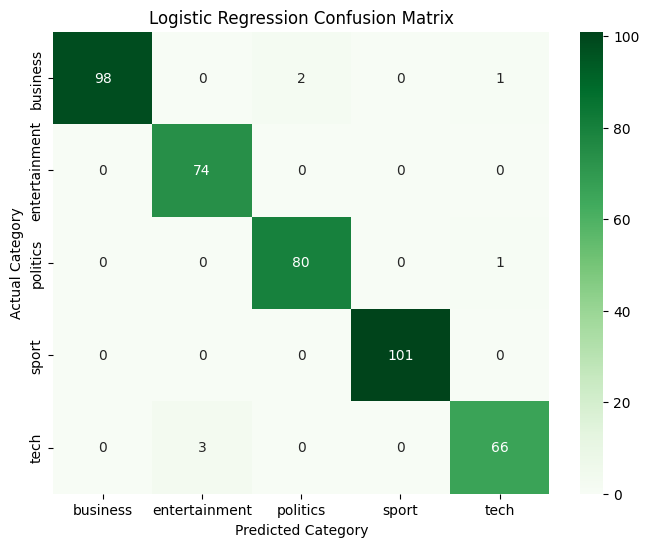

In [57]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

lr_cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=lr_model.classes_,
    yticklabels=lr_model.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [58]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(
    {
        "tfidf": tfidf,
        "lr_model": lr_model
    },
    "models/news_classifier.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [59]:

def load_classifier():

    saved_model = joblib.load(
        "models/news_classifier.pkl"
    )

    return saved_model['tfidf'], saved_model['lr_model']

In [60]:
# Load the saved TF-IDF vectorizer and Logistic Regression model
tfidf, lr_model = load_classifier()

# Enter ONE new article as a string (not a list)
article = """
The Indian cricket team won the international match.
The players performed exceptionally well throughout the game.
"""

# Apply the same preprocessing used during model training
processed_article = preprocess_text(article)

# Convert the processed article into TF-IDF features
article_tfidf = tfidf.transform([processed_article])

# Predict the news category
prediction = lr_model.predict(article_tfidf)

# Get the model's probability scores and highest score
probabilities = lr_model.predict_proba(article_tfidf)
confidence = probabilities.max()

print("Predicted Category:", prediction[0])
print("Confidence:", round(confidence * 100, 2), "%")

# Optional: display probability for each category
for category, probability in zip(lr_model.classes_, probabilities[0]):
    print(f"{category}: {probability * 100:.2f}%")

Predicted Category: sport
Confidence: 71.32 %
business: 7.30%
entertainment: 6.16%
politics: 3.70%
sport: 71.32%
tech: 11.52%
